# Decision Tree from Scratch

**Goal:** Implement a CART-style decision tree classifier in pure NumPy and compare it with scikit-learn on a real dataset.

**Dataset:** `loan_data.csv` – 45,000 loan applications

**Approach:** The tree recursively picks the feature/threshold with the highest **information gain** (entropy-based), stopping at `max_depth` or `min_samples_split`; leaves predict the majority class.

In [1]:
import numpy as np
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Implementation from scratch

In [2]:
import numpy as np
from collections import Counter

class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None,*,value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        
    def is_leaf_node(self):
        return self.value is not None


class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=100, n_features=None):
        self.min_samples_split=min_samples_split
        self.max_depth=max_depth
        self.n_features=n_features
        self.root=None

    def fit(self, X, y):
        self.n_features = X.shape[1] if not self.n_features else min(X.shape[1],self.n_features)
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_feats = X.shape
        n_labels = len(np.unique(y))

        # check the stopping criteria
        if (depth>=self.max_depth or n_labels==1 or n_samples<self.min_samples_split):
            leaf_value = self._most_common_label(y)
            return Node(value=leaf_value)

        feat_idxs = np.random.choice(n_feats, self.n_features, replace=False)

        # find the best split
        best_feature, best_thresh = self._best_split(X, y, feat_idxs)

        # create child nodes
        left_idxs, right_idxs = self._split(X[:, best_feature], best_thresh)
        left = self._grow_tree(X[left_idxs, :], y[left_idxs], depth+1)
        right = self._grow_tree(X[right_idxs, :], y[right_idxs], depth+1)
        return Node(best_feature, best_thresh, left, right)


    def _best_split(self, X, y, feat_idxs):
        best_gain = -1
        split_idx, split_threshold = None, None

        for feat_idx in feat_idxs:
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)

            for thr in thresholds:
                # calculate the information gain
                gain = self._information_gain(y, X_column, thr)

                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_threshold = thr

        return split_idx, split_threshold


    def _information_gain(self, y, X_column, threshold):
        # parent entropy
        parent_entropy = self._entropy(y)

        # create children
        left_idxs, right_idxs = self._split(X_column, threshold)

        if len(left_idxs) == 0 or len(right_idxs) == 0:
            return 0
        
        # calculate the weighted avg. entropy of children
        n = len(y)
        n_l, n_r = len(left_idxs), len(right_idxs)
        e_l, e_r = self._entropy(y[left_idxs]), self._entropy(y[right_idxs])
        child_entropy = (n_l/n) * e_l + (n_r/n) * e_r

        # calculate the IG
        information_gain = parent_entropy - child_entropy
        return information_gain

    def _split(self, X_column, split_thresh):
        left_idxs = np.argwhere(X_column <= split_thresh).flatten()
        right_idxs = np.argwhere(X_column > split_thresh).flatten()
        return left_idxs, right_idxs

    def _entropy(self, y):
        hist = np.bincount(y)
        ps = hist / len(y)
        return -np.sum([p * np.log(p) for p in ps if p>0])


    def _most_common_label(self, y):
        counter = Counter(y)
        value = counter.most_common(1)[0][0]
        return value

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)
        



## Load the data

In [3]:
df=pd.read_csv('../data/loan_data.csv')

In [4]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


## Exploratory data analysis

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int64  
 12  previous_loan_defaults_on_file  

In [6]:
df.shape

(45000, 14)

In [7]:
df.isnull().sum()

person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

## Outlier detection (IQR)

In [8]:
num_cols = ["person_age", "person_income","person_emp_exp","loan_amnt","loan_int_rate","loan_percent_income","cb_person_cred_hist_length","credit_score",     ]



for col in num_cols:
    Q1 = np.percentile(df[col], 25)
    Q3 = np.percentile(df[col], 75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers_count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {outliers_count} outliers (range: {lower:.2f} to {upper:.2f})")

person_age: 2188 outliers (range: 15.00 to 39.00)
person_income: 2218 outliers (range: -25673.88 to 168667.12)
person_emp_exp: 1724 outliers (range: -9.50 to 18.50)
loan_amnt: 2348 outliers (range: -5855.88 to 23093.12)
loan_int_rate: 124 outliers (range: 1.99 to 19.59)
loan_percent_income: 744 outliers (range: -0.11 to 0.37)
cb_person_cred_hist_length: 1366 outliers (range: -4.50 to 15.50)
credit_score: 467 outliers (range: 497.50 to 773.50)


## Feature distributions

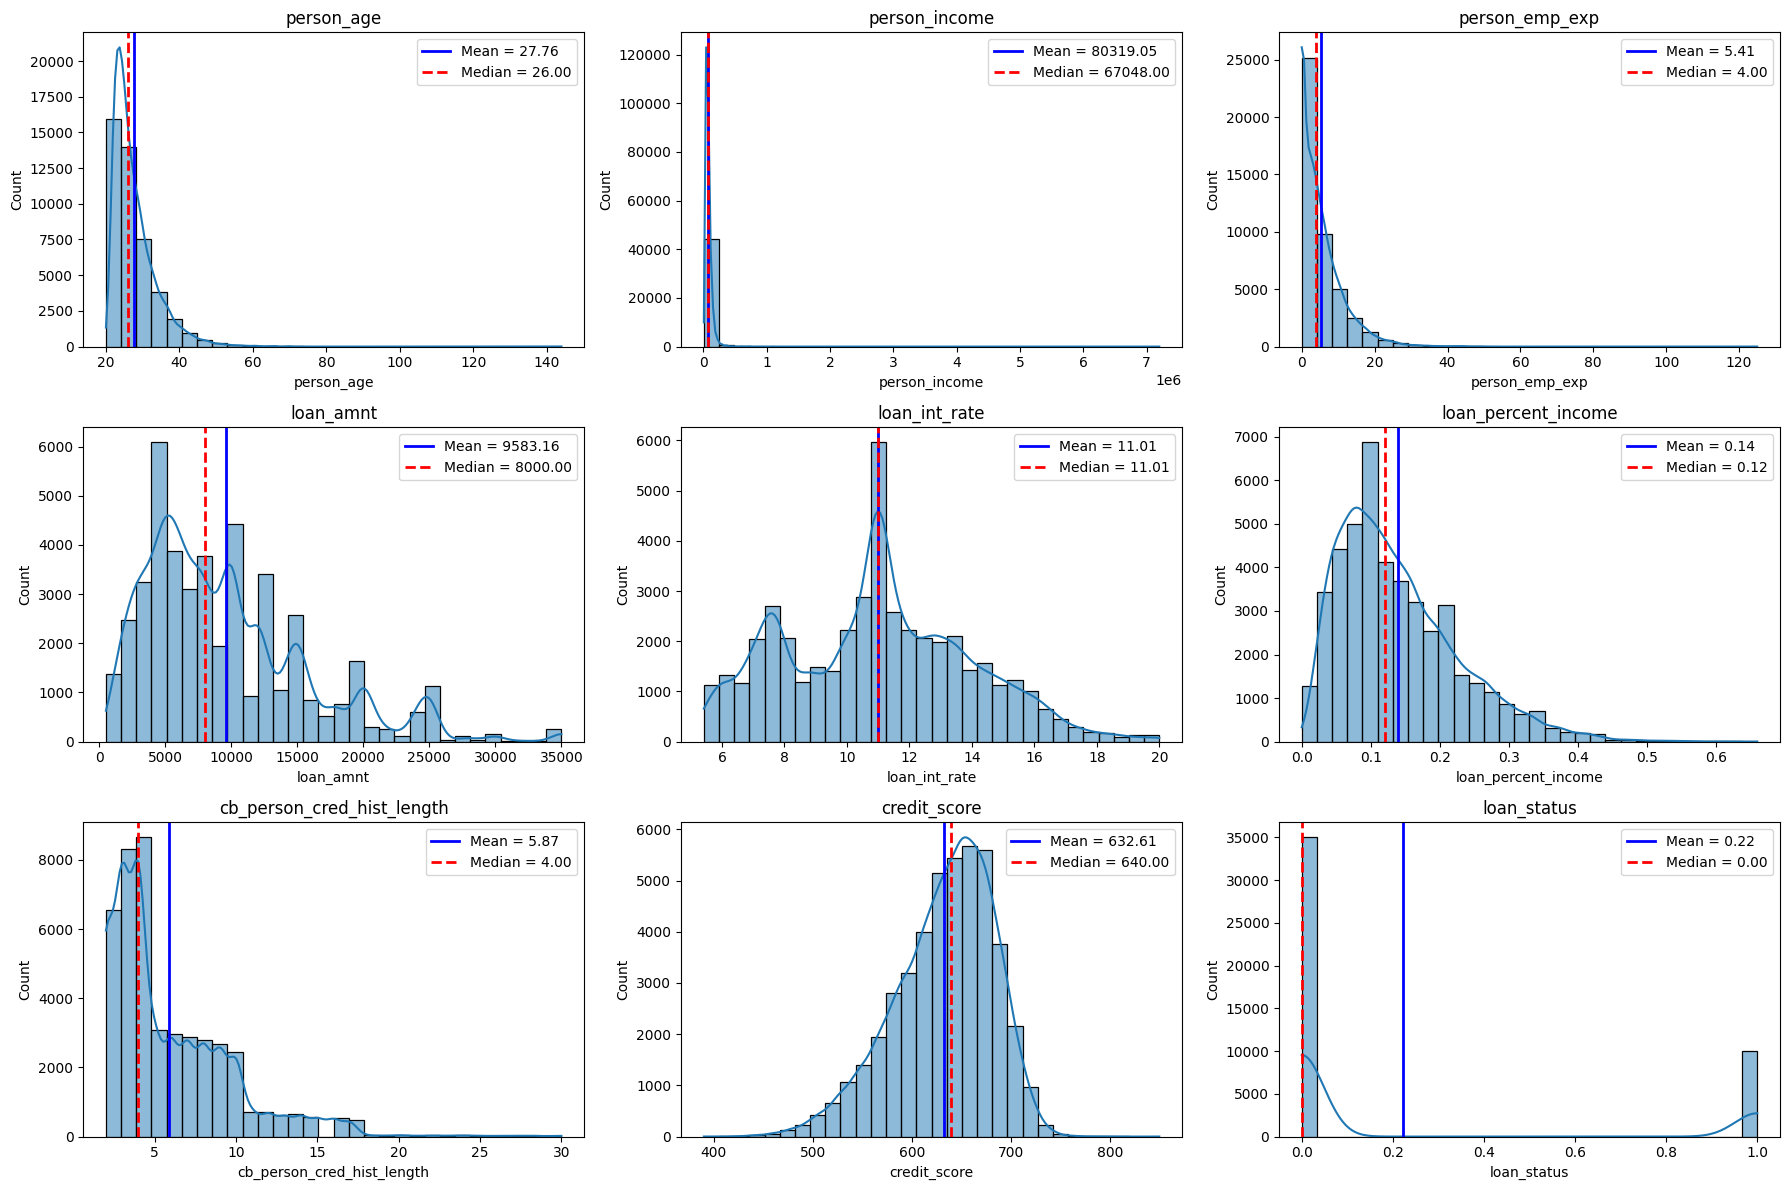

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
df = pd.read_csv("../data/loan_data.csv")

# Numeric columns only
numeric_df = df.select_dtypes(include=['int64', 'float64'])

features = numeric_df.columns

n_cols = 3
n_rows = (len(features) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(features):

    sns.histplot(
        data=numeric_df,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    mean_val = numeric_df[col].mean()
    median_val = numeric_df[col].median()

    axes[i].axvline(
        mean_val,
        color='blue',
        linestyle='-',
        linewidth=2,
        label=f"Mean = {mean_val:.2f}"
    )

    axes[i].axvline(
        median_val,
        color='red',
        linestyle='--',
        linewidth=2,
        label=f"Median = {median_val:.2f}"
    )

    axes[i].set_title(col, fontsize=12)
    axes[i].legend()

# Remove empty plots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## Feature scaling

In [10]:
from sklearn.preprocessing import RobustScaler
num_cols = ["person_age", "person_income","person_emp_exp","loan_amnt","loan_int_rate","loan_percent_income","cb_person_cred_hist_length","credit_score",     ]

scaler=RobustScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])


In [11]:
df

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,-0.666667,female,Master,0.100854,-0.571429,RENT,3.730699,PERSONAL,1.138636,3.083333,-0.2,-1.144928,No,1
1,-0.833333,female,High School,-1.127215,-0.571429,OWN,-0.967218,EDUCATION,0.029545,-0.333333,-0.4,-1.971014,Yes,0
2,-0.166667,female,High School,-1.124004,-0.142857,MORTGAGE,-0.345435,MEDICAL,0.422727,2.666667,-0.2,-0.072464,No,1
3,-0.500000,female,Bachelor,0.261499,-0.571429,RENT,3.730699,MEDICAL,0.959091,2.666667,-0.4,0.507246,No,1
4,-0.333333,male,Master,-0.018792,-0.428571,RENT,3.730699,MEDICAL,0.740909,3.416667,0.0,-0.782609,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,0.166667,male,Associate,-0.392650,0.285714,RENT,0.967218,MEDICAL,1.056818,1.583333,-0.2,0.072464,No,1
44996,1.833333,female,Associate,-0.025687,1.857143,RENT,0.138174,HOMEIMPROVEMENT,0.695455,0.166667,1.4,-0.275362,No,1
44997,1.166667,male,Associate,-0.208006,0.428571,RENT,-0.722512,DEBTCONSOLIDATION,-0.225000,-0.583333,1.2,0.405797,No,1
44998,0.500000,male,Bachelor,-0.697413,0.000000,RENT,0.552696,EDUCATION,0.504545,2.000000,0.4,-0.521739,No,1


In [12]:
from sklearn.preprocessing import  OrdinalEncoder,LabelEncoder,OneHotEncoder

## Data cleaning & preprocessing

In [13]:
encoder_gender = LabelEncoder()
df['Gender_level_encoded'] = encoder_gender.fit_transform(df['person_gender'])
df[['person_gender','Gender_level_encoded']]

,person_gender,Gender_level_encoded
0,female,0
1,female,0
2,female,0
3,female,0
4,male,1
...,...,...
44995,male,1
44996,female,0
44997,male,1
44998,male,1


In [14]:
encoder_person_education = OrdinalEncoder(categories=[['High School', 'Bachelor', 'Master','Associate','Doctorate']])
df['person_education_Type_encoded'] = encoder_person_education.fit_transform(df[['person_education']])
df[['person_education', 'person_education_Type_encoded']]

,person_education,person_education_Type_encoded
0,Master,2.0
1,High School,0.0
2,High School,0.0
3,Bachelor,1.0
4,Master,2.0
...,...,...
44995,Associate,3.0
44996,Associate,3.0
44997,Associate,3.0
44998,Bachelor,1.0


In [15]:
onehot_cols = ['person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']

encoder_onehot = OneHotEncoder(sparse_output=False, dtype=int)
onehot_array = encoder_onehot.fit_transform(df[onehot_cols])
onehot_df = pd.DataFrame(onehot_array, columns=encoder_onehot.get_feature_names_out(onehot_cols), index=df.index)

df = pd.concat([df, onehot_df], axis=1)
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_No,previous_loan_defaults_on_file_Yes
0,-0.666667,female,Master,0.100854,-0.571429,RENT,3.730699,PERSONAL,1.138636,3.083333,...,0,1,0,0,0,0,1,0,1,0
1,-0.833333,female,High School,-1.127215,-0.571429,OWN,-0.967218,EDUCATION,0.029545,-0.333333,...,1,0,0,1,0,0,0,0,0,1
2,-0.166667,female,High School,-1.124004,-0.142857,MORTGAGE,-0.345435,MEDICAL,0.422727,2.666667,...,0,0,0,0,0,1,0,0,1,0
3,-0.500000,female,Bachelor,0.261499,-0.571429,RENT,3.730699,MEDICAL,0.959091,2.666667,...,0,1,0,0,0,1,0,0,1,0
4,-0.333333,male,Master,-0.018792,-0.428571,RENT,3.730699,MEDICAL,0.740909,3.416667,...,0,1,0,0,0,1,0,0,1,0


In [16]:
df = df.drop(columns=['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file'])
df.head()

,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status,Gender_level_encoded,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_No,previous_loan_defaults_on_file_Yes
0,-0.666667,0.100854,-0.571429,3.730699,1.138636,3.083333,-0.2,-1.144928,1,0,...,0,1,0,0,0,0,1,0,1,0
1,-0.833333,-1.127215,-0.571429,-0.967218,0.029545,-0.333333,-0.4,-1.971014,0,0,...,1,0,0,1,0,0,0,0,0,1
2,-0.166667,-1.124004,-0.142857,-0.345435,0.422727,2.666667,-0.2,-0.072464,1,0,...,0,0,0,0,0,1,0,0,1,0
3,-0.500000,0.261499,-0.571429,3.730699,0.959091,2.666667,-0.4,0.507246,1,0,...,0,1,0,0,0,1,0,0,1,0
4,-0.333333,-0.018792,-0.428571,3.730699,0.740909,3.416667,0.0,-0.782609,1,1,...,0,1,0,0,0,1,0,0,1,0


## Correlation analysis

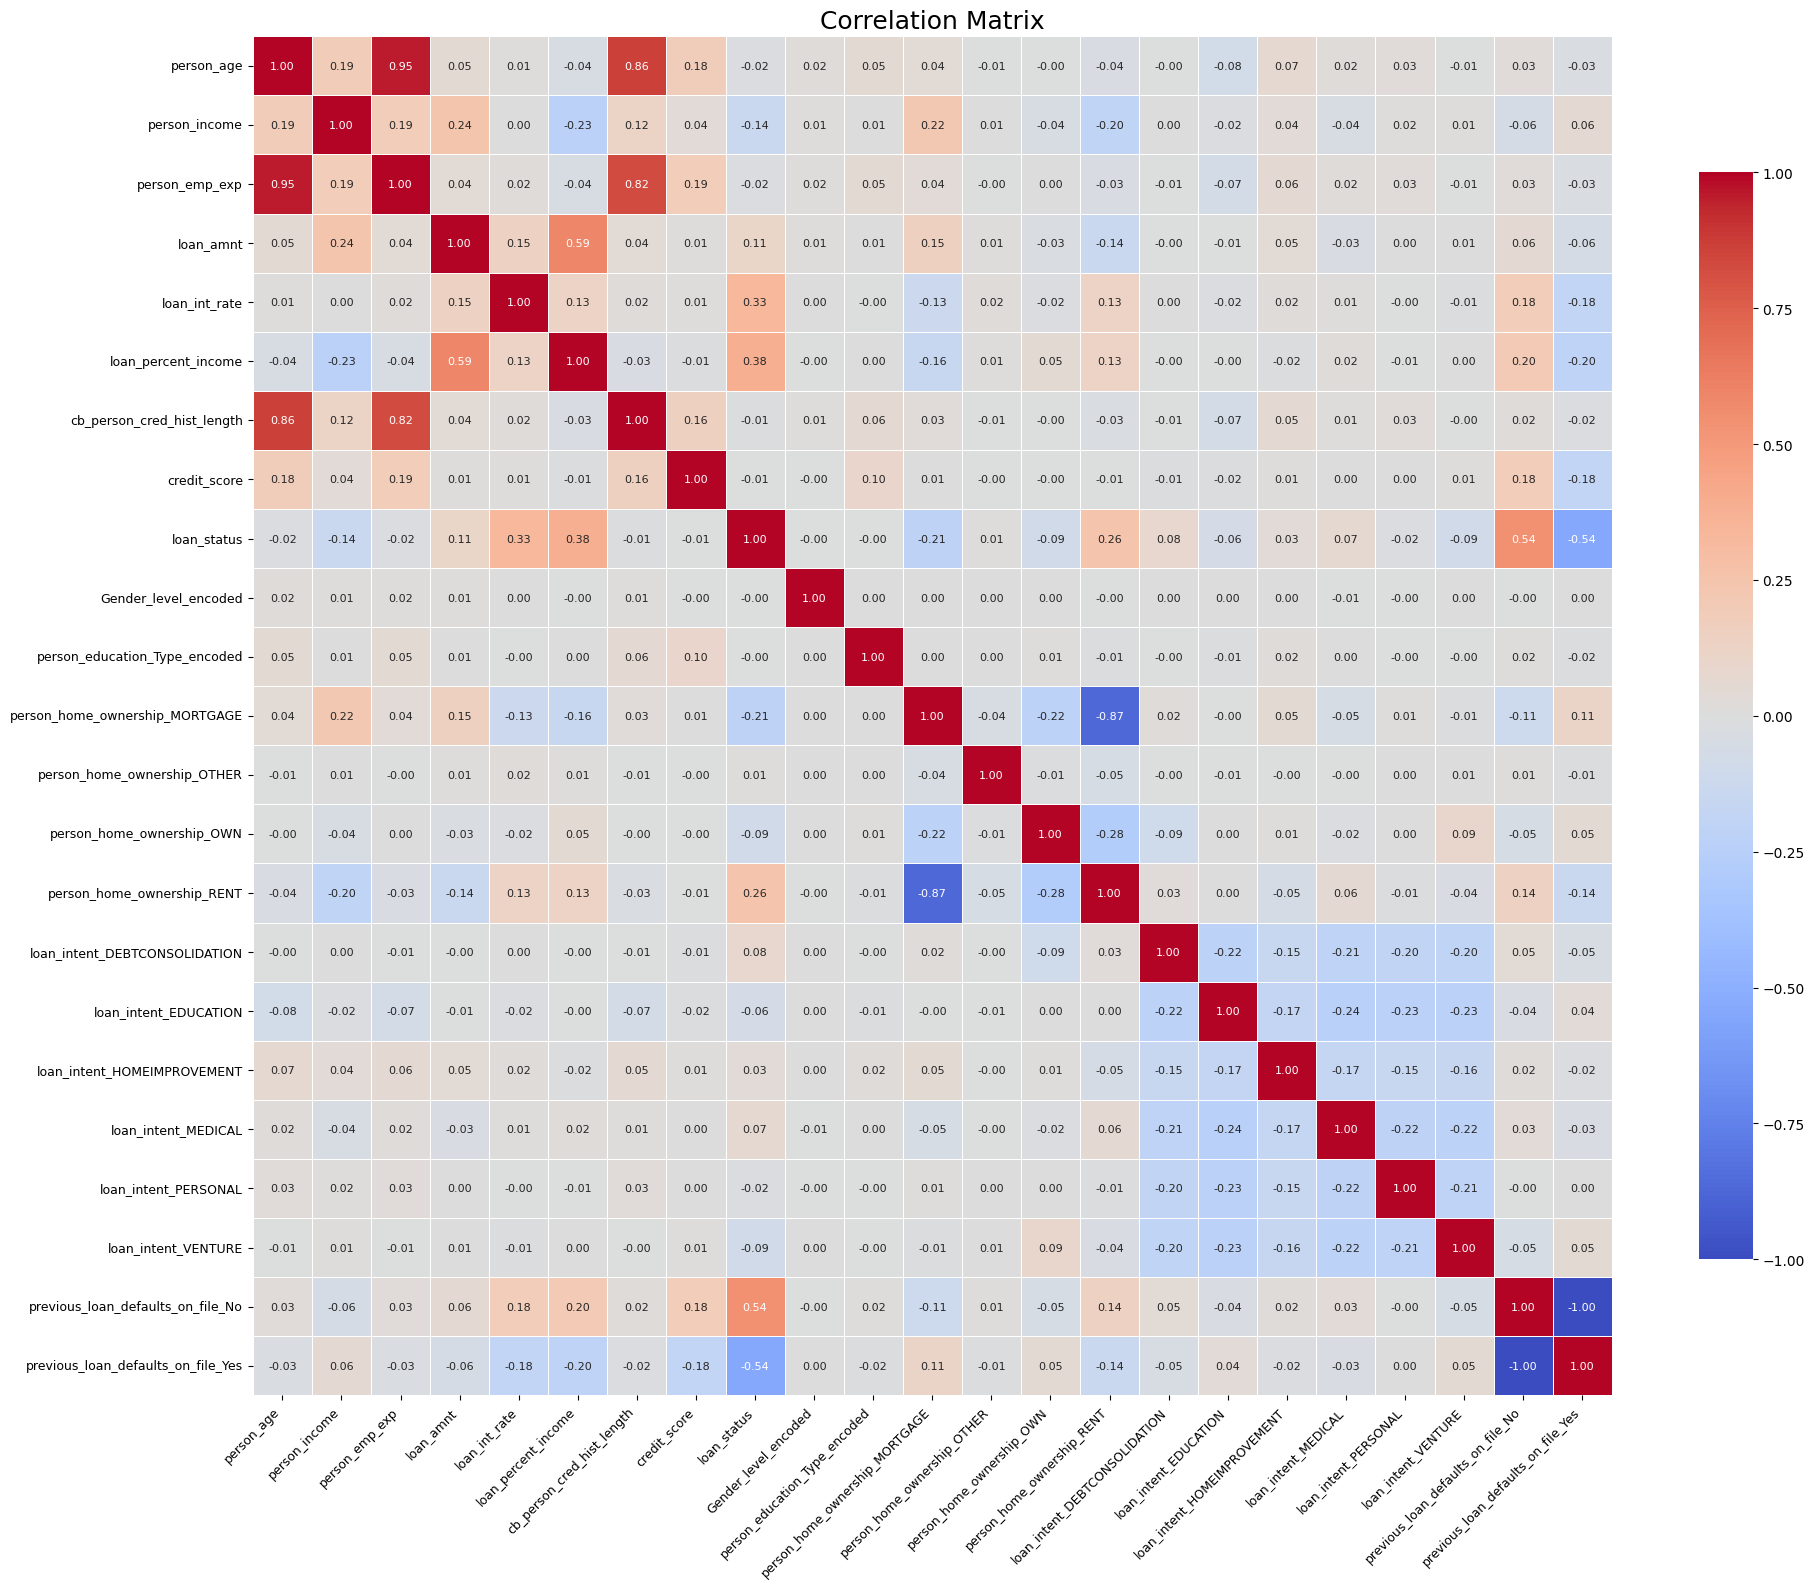

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20,16))

corr = df.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",          
    cmap="coolwarm",    
    center=0,
    linewidths=0.5,
    square=True,
    annot_kws={"size": 8},  
    cbar_kws={"shrink": 0.8}
)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.title("Correlation Matrix", fontsize=18)
plt.tight_layout()
plt.show()

In [18]:
print(df.columns)

Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'loan_status', 'Gender_level_encoded',
       'person_education_Type_encoded', 'person_home_ownership_MORTGAGE',
       'person_home_ownership_OTHER', 'person_home_ownership_OWN',
       'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION',
       'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT',
       'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE',
       'previous_loan_defaults_on_file_No',
       'previous_loan_defaults_on_file_Yes'],
      dtype='object')


In [19]:
X = df.drop('loan_status', axis=1)   
y = df['loan_status']      

## Train / test split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Model training

In [21]:
my_tree = DecisionTree(
    max_depth=100,
    min_samples_split=2
)

my_tree.fit(X_train.values, y_train.values)

In [22]:
from sklearn.tree import DecisionTreeClassifier

sk_tree = DecisionTreeClassifier(
    criterion="entropy",   
    max_depth=100,
    min_samples_split=2,
    random_state=42
)

sk_tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",100
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [23]:
my_pred = my_tree.predict(X_test.values)

sk_pred = sk_tree.predict(X_test)

## Evaluation

In [24]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print(f"My Tree Accuracy      : {accuracy_score(y_test, my_pred):.4f}")
print(f"Scikit-learn Accuracy : {accuracy_score(y_test, sk_pred):.4f}")

print("\n================ My Tree ================\n")
print(classification_report(y_test, my_pred))

print("\n============= Scikit-learn ==============\n")
print(classification_report(y_test, sk_pred))

My Tree Accuracy      : 0.9027
Scikit-learn Accuracy : 0.9014

================ My Tree ================

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      7000
           1       0.78      0.77      0.78      2000

    accuracy                           0.90      9000
   macro avg       0.86      0.86      0.86      9000
weighted avg       0.90      0.90      0.90      9000


============= Scikit-learn ==============

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      7000
           1       0.78      0.78      0.78      2000

    accuracy                           0.90      9000
   macro avg       0.86      0.86      0.86      9000
weighted avg       0.90      0.90      0.90      9000



## Results & conclusion

| Model | Test accuracy |
|---|---|
| From scratch | **0.90** |
| scikit-learn `DecisionTreeClassifier` | 0.90 |

The from-scratch tree matches scikit-learn's accuracy, which confirms the information-gain split logic is correct.